# Food-101: 2 classes with train / val / test split


- The official test set is kept as it is
- A validation set (20%) is taken from the official train set

## 1. Import libraries

In [1]:
import random
import shutil
import sys
from pathlib import Path

import cv2
import torch
import matplotlib.pyplot as plt
from torchvision.datasets import Food101

sys.path.append("..")

from src.utils import DATA_DIR, DATASET_DIR, TRAIN_DIR, VAL_DIR, TEST_DIR

print("OpenCV:", cv2.__version__)
print("torch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

OpenCV: 5.0.0
torch: 2.14.1
MPS available: True


## 2. Food-101 download

The dataset is ~5 GB, so the first download takes a long time.
`download=True`: if the file already exists, it does not download it again.

In [2]:
train_ds = Food101(root=DATA_DIR, split="train", download=True)
test_ds = Food101(root=DATA_DIR, split="test", download=True)

print("Train images count:", len(train_ds))
print("Test images count:", len(test_ds))

Train images count: 75750
Test images count: 25250


## 3. Explore the dataset

In [3]:
print("Classes:", len(train_ds.classes))
print("First 10 classes:", train_ds.classes[:10])

for name in ["bibimbap", "fried_rice"]:
    print(name, "-> label:", train_ds.classes.index(name))

Classes: 101
First 10 classes: ['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito']
bibimbap -> label: 7
fried_rice -> label: 44


## 4. Read one image with OpenCV

OpenCV reads images in **BGR** order, but matplotlib expects **RGB**, so we convert before showing.

File: /Users/asadbek/Documents/github_projects/korean-food-binary-classifier/data/food-101/images/churros/1004234.jpg
Shape (H, W, C): (512, 512, 3)
Dtype: uint8 | pixel range: 0 - 255
Label: 23 -> churros


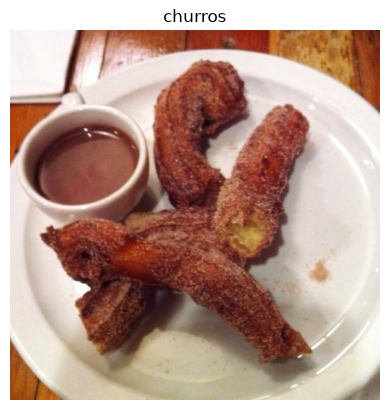

In [4]:
img_path = train_ds._image_files[0]
label = train_ds._labels[0]

img_bgr = cv2.imread(str(img_path))                  # BGR, NumPy array
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)   # convert to RGB

print("File:", img_path)
print("Shape (H, W, C):", img_rgb.shape)
print("Dtype:", img_rgb.dtype, "| pixel range:", img_rgb.min(), "-", img_rgb.max())
print("Label:", label, "->", train_ds.classes[label])

plt.imshow(img_rgb)
plt.title(train_ds.classes[label])
plt.axis("off")
plt.show()

## 5. Collect images of the selected classes

For each selected class we collect a sorted list of image paths.
Sorting makes the result independent of the OS file order.

In [5]:
KEEP_CLASSES = ["bibimbap", "fried_rice"]
SPLITS = ("train", "val", "test")


def collect_class_images(ds, keep):
    """Return {class_name: sorted list of image paths} for the selected classes."""
    missing = [c for c in keep if c not in ds.classes]
    if missing:
        raise ValueError(f"Unknown classes: {missing}")

    images = {cls: [] for cls in keep}
    for img_path, label in zip(ds._image_files, ds._labels):
        cls = ds.classes[label]
        if cls in images:
            images[cls].append(Path(img_path))

    return {cls: sorted(paths) for cls, paths in images.items()}


train_images = collect_class_images(train_ds, KEEP_CLASSES)
test_images = collect_class_images(test_ds, KEEP_CLASSES)

for cls in KEEP_CLASSES:
    print(f"{cls:11s} | official train: {len(train_images[cls])} | official test: {len(test_images[cls])}")

bibimbap    | official train: 750 | official test: 250
fried_rice  | official train: 750 | official test: 250


## 6. Split train into train and val

1. Shuffle the official train images (with a fixed seed, so the split is reproducible)
2. The last 20% become validation images

We only look at the counts here. Nothing is copied yet.

In [6]:
SEED = 42
VAL_RATIO = 0.2  # 20% of the official train images become validation images

rng = random.Random(SEED)  # local generator: same SEED -> same split

train_files = {}
val_files = {}

for cls in KEEP_CLASSES:
    paths = list(train_images[cls])
    rng.shuffle(paths)

    val_count = int(len(paths) * VAL_RATIO)
    train_count = len(paths) - val_count

    train_files[cls] = paths[:train_count]
    val_files[cls] = paths[train_count:]

    print(f"{cls:11s} | train: {len(train_files[cls])} | val: {len(val_files[cls])} | test: {len(test_images[cls])}")

bibimbap    | train: 600 | val: 150 | test: 250
fried_rice  | train: 600 | val: 150 | test: 250


## 7. Copy files into `dataset/`

First the old `train/val/test` folders are removed, so the split is always rebuilt from scratch.
Only these three folders are removed. The raw Food-101 data in `DATA_DIR` is never touched.

In [7]:
# Remove old split folders
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    if split_dir.exists():
        shutil.rmtree(split_dir)

# Copy files
for cls in KEEP_CLASSES:
    for split_dir, files in [
        (TRAIN_DIR, train_files[cls]),
        (VAL_DIR, val_files[cls]),
        (TEST_DIR, test_images[cls]),
    ]:
        out_dir = split_dir / cls
        out_dir.mkdir(parents=True, exist_ok=True)
        for file_path in files:
            shutil.copy(file_path, out_dir / file_path.name)

print("Ready!")

Ready!


## 8. Check counts

Expected for each class: train 600, val 150, test 250.

In [8]:
for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:
    for cls in KEEP_CLASSES:
        n = len(list((split_dir / cls).glob("*.jpg")))
        print(f"{split_dir.name:5s} | {cls:11s} | {n} images")

train | bibimbap    | 600 images
train | fried_rice  | 600 images
val   | bibimbap    | 150 images
val   | fried_rice  | 150 images
test  | bibimbap    | 250 images
test  | fried_rice  | 250 images


## 9. Check for data leakage

The same image must not appear in two different splits.
All numbers below should be 0.

In [9]:
for cls in KEEP_CLASSES:
    train_names = {p.name for p in (TRAIN_DIR / cls).glob("*.jpg")}
    val_names = {p.name for p in (VAL_DIR / cls).glob("*.jpg")}
    test_names = {p.name for p in (TEST_DIR / cls).glob("*.jpg")}

    print(
        f"{cls:11s} | train&val: {len(train_names & val_names)}"
        f" | train&test: {len(train_names & test_names)}"
        f" | val&test: {len(val_names & test_names)}"
    )

bibimbap    | train&val: 0 | train&test: 0 | val&test: 0
fried_rice  | train&val: 0 | train&test: 0 | val&test: 0


## 10. Image size

A CNN needs images of the same size, so first we check the current sizes.

In [10]:
sizes = []
for cls in KEEP_CLASSES:
    for p in sorted((TRAIN_DIR / cls).glob("*.jpg"))[:50]:
        h, w = cv2.imread(str(p)).shape[:2]
        sizes.append((h, w))

heights = [s[0] for s in sizes]
widths = [s[1] for s in sizes]
print("Height: min", min(heights), "| max", max(heights))
print("Width:  min", min(widths), "| max", max(widths))

Height: min 286 | max 512
Width:  min 341 | max 512


## 11. Visualize and test `cv2.resize`

Top row: original images. Bottom row: resized to 224x224.

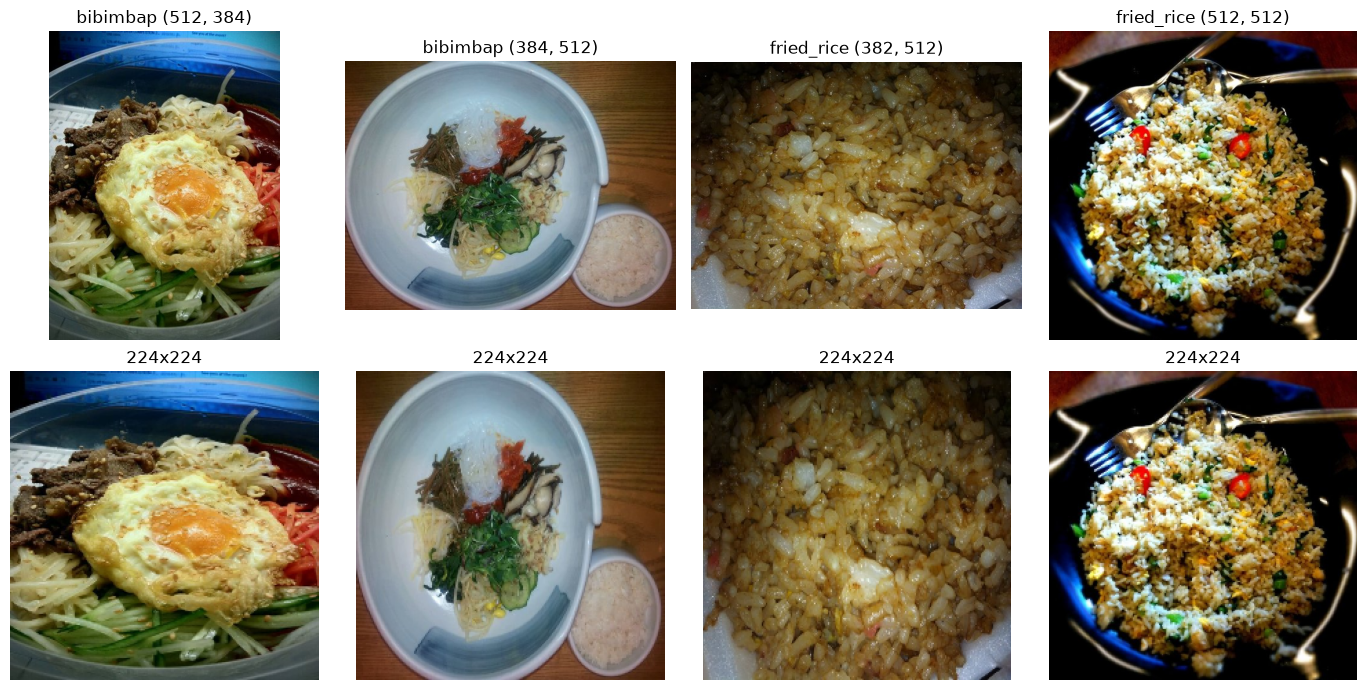

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

samples = []
for cls in KEEP_CLASSES:
    samples += [(cls, p) for p in sorted((TRAIN_DIR / cls).glob("*.jpg"))[:2]]

for i, (cls, p) in enumerate(samples):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    small = cv2.resize(img, (224, 224))  # (width, height)

    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{cls} {img.shape[:2]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(small)
    axes[1, i].set_title("224x224")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()